# Título

**Autores:** Artur Lacerda Pugoni, Guilherme da Cunha Fonseca, Sarah Félix Stocler  
**Repositório do Projeto:** [\[GitHub\]](https://github.com/r3lc0ts/Projeto-AEDV)

---

## 1. Introdução:
Texto

## 2. Descrição e Preparação dos Dados
Os dados foram retirados Portal Brasileiro de Dados Abertos (Ministério do Turismo / Polícia Federal). 
* **Nota Metodológica:** Os registros refletem o **estado de entrada (UF de desembarque/fronteira)** no Brasil, e não necessariamente o destino final do turista. Além disso, os anos de **2020, 2021 e 2022** apresentam registros zerados na base original em decorrência da pandemia e serão tratados separadamente para não distorcer as análises de tendência histórica.

In [1]:
# Download e extração automatizada da base bruta via GitHub Releases

import urllib.request
import zipfile
from pathlib import Path

url_dados = "https://github.com/r3lc0ts/Projeto-AEDV/releases/download/v1.0.0/raw.zip"
pasta_raw = Path("../data/raw")
arquivo_zip = Path("../data/raw.zip")

if not pasta_raw.exists() or len(list(pasta_raw.glob("chegadas_*.csv"))) == 0:
    pasta_raw.mkdir(parents=True, exist_ok=True)
    print("Baixando dados brutos da Release do GitHub...")
    urllib.request.urlretrieve(url_dados, arquivo_zip)
    
    print("Extraindo arquivos em data/raw/...")
    with zipfile.ZipFile(arquivo_zip, "r") as zip_ref:
        zip_ref.extractall(pasta_raw.parent)
        
    if arquivo_zip.exists():
        arquivo_zip.unlink() # Remove o zip após descompactar
    print("Download e extração concluídos com sucesso!")
else:
    print(f"Base de dados bruta já presente em {pasta_raw}.")

Base de dados bruta já presente em ..\data\raw.


In [ ]:
# Carregamento e limpeza da base de dados

import pandas as pd
import numpy as np
import unicodedata
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from pathlib import Path

# Procura no caminho todos os arquivos que começam com chegadas e terminam com .csv e coloca em ordem cronológica
arquivos = sorted(Path("../data/raw").glob("chegadas_*.csv"))
print(f"Total de arquivos encontrados: {len(arquivos)}")
# Converte o nome do mês em número para organizar e padroniar entre as tabelas de cada ano
MESES = {
    "janeiro": 1, "fevereiro": 2, "marco": 3, "abril": 4, "maio": 5, "junho": 6,
    "julho": 7, "agosto": 8, "setembro": 9, "outubro": 10, "novembro": 11, "dezembro": 12
}
# Função para limpar o texto (snake_case)
def limpar(texto):
    texto = unicodedata.normalize("NFKD", str(texto).strip().lower())
    return texto.encode("ascii", "ignore").decode().replace(" ", "_")

def carregar(arquivo):
    # Tenta ler em utf-8 primeiro para não quebrar acentos nos anos recentes; senão usa latin-1
    # lê o arquivo inteiro de uma vez e só então decidir o tipo de cada coluna
    try:
        df = pd.read_csv(arquivo, sep=";", encoding="utf-8", low_memory=False)
    except UnicodeDecodeError:
        df = pd.read_csv(arquivo, sep=";", encoding="latin-1", low_memory=False)
        
    df.columns = [limpar(c) for c in df.columns]
    # Remover colunas inúteis
    df = df.drop(columns=[c for c in df.columns if c.startswith(("ordem", "cod"))])
    df = df.rename(columns={"via_de_acesso": "via"})

    # Para cada coluna de texto converte para string e remove espaços extras no começo e no fim
    for col in ["continente", "pais", "uf", "via"]:
        if col in df.columns:
            df[col] = df[col].astype(str).str.strip()

    # .map(): pega cada valor da coluna passa por uma função e devolve o resultado
    # lambda m: def converter(m)
    # busca a chave. Se achar, devolve o valor. Se não achar, devolve o segundo argumento
    df["mes"] = df["mes"].map(lambda m: MESES.get(limpar(m), pd.to_numeric(m, errors="coerce")))
    # se não for número altera para NaN
    df["chegadas"] = pd.to_numeric(df["chegadas"], errors="coerce")
    return df
# dicionário onde a chave é o nome do arquivo sem extensão
# empilha todas as tabelas em uma só
tabelas = {arquivo.stem: carregar(arquivo) for arquivo in arquivos}
chegadas = pd.concat(tabelas.values(), ignore_index=True)

# Padroniza chegadas
chegadas["via"] = chegadas["via"].replace({"Aéreo": "Aérea", "Marítimo": "Marítima"})

# Agrupa linhas iguais, elimina duplicatas da coluna chegada, se todos os valores forem NaN mantém NaN e não 0
chaves = ["continente", "pais", "uf", "via", "ano", "mes"]
chegadas = (
    chegadas
    .groupby(chaves, as_index=False, dropna=False)["chegadas"]
    .sum(min_count=1)
)

# Salva a base limpa em data/processed
Path("../data/processed").mkdir(parents=True, exist_ok=True)
chegadas.to_csv("../data/processed/chegadas_limpo.csv", index=False, encoding="utf-8")

print(f"Base consolidada com sucesso! Total de linhas: {len(chegadas):,}")
display(chegadas.head())

Total de arquivos encontrados: 32
Base consolidada com sucesso! Total de linhas: 716,975


,continente,pais,uf,via,ano,mes,chegadas
0,América Central e Caribe,Costa Rica,Acre,Aérea,2014,1,0.0
1,América Central e Caribe,Costa Rica,Acre,Aérea,2014,2,0.0
2,América Central e Caribe,Costa Rica,Acre,Aérea,2014,3,0.0
3,América Central e Caribe,Costa Rica,Acre,Aérea,2014,4,0.0
4,América Central e Caribe,Costa Rica,Acre,Aérea,2014,5,0.0


3.	Qual mês recebe mais turistas ao longo do ano?

,mes,chegadas,nome_mes
0,1,654895.34375,Janeiro
1,2,518273.25000,Fevereiro
11,12,437514.25000,Dezembro
2,3,432654.40625,Março
10,11,337349.81250,Novembro
6,7,326636.25000,Julho
9,10,312989.43750,Outubro
3,4,305101.65625,Abril
7,8,298709.59375,Agosto
8,9,271483.78125,Setembro


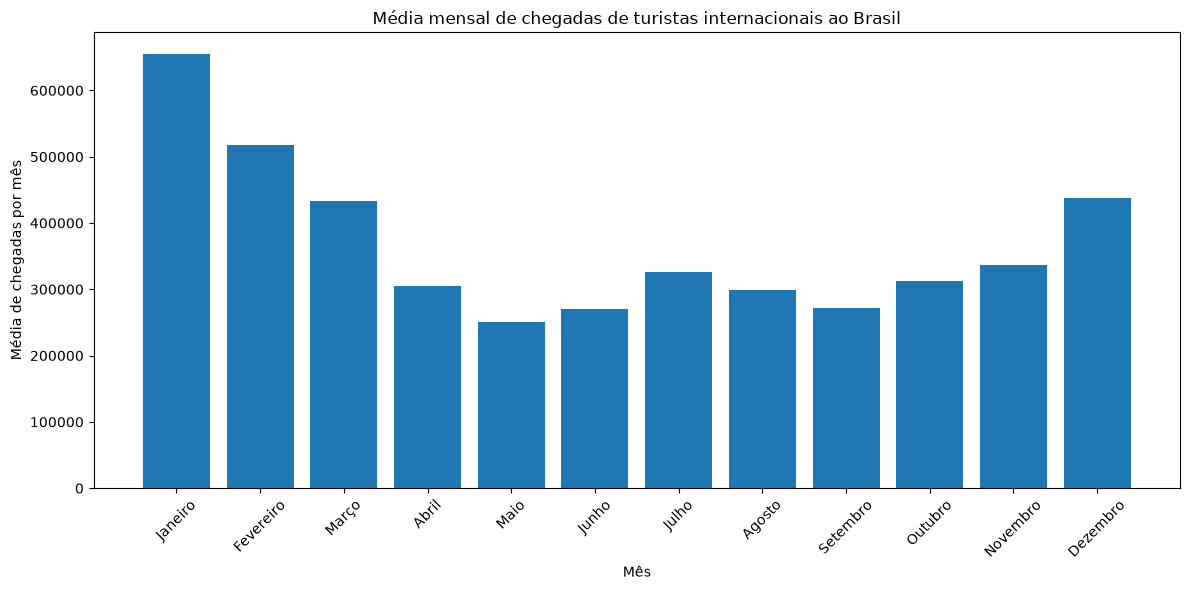

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt


chegadas = pd.read_csv("../data/processed/chegadas_limpo.csv")


por_ano_mes = (
    chegadas.groupby(["ano", "mes"], as_index=False)["chegadas"].sum(min_count=1)
)


media_mensal = (
    por_ano_mes.groupby("mes", as_index=False)["chegadas"].mean()
)


nomes_meses = {
    1: "Janeiro",
    2: "Fevereiro",
    3: "Março",
    4: "Abril",
    5: "Maio",
    6: "Junho",
    7: "Julho",
    8: "Agosto",
    9: "Setembro",
    10: "Outubro",
    11: "Novembro",
    12: "Dezembro"
}

media_mensal["nome_mes"] = media_mensal["mes"].map(nomes_meses)



ranking = media_mensal.sort_values("chegadas", ascending=False)

display(ranking)


plt.figure(figsize=(12, 6))

plt.bar(
    media_mensal["nome_mes"],
    media_mensal["chegadas"]
)

plt.title("Média mensal de chegadas de turistas internacionais ao Brasil")
plt.xlabel("Mês")
plt.ylabel("Média de chegadas por mês")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


4.	Quais países mais visitam o Brasil ao longo do tempo?

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


chegadas = pd.read_csv("../data/processed/chegadas_limpo.csv")

agrupamento_pais_via = chegadas.groupby(["pais", "via"], as_index=False)["chegadas"].sum()

display(agrupamento_pais_via.head(20))

,pais,via,chegadas
0,Alemanha,Aérea,5672555.0
1,Alemanha,Fluvial,31312.0
2,Alemanha,Marítima,189492.0
3,Alemanha,Terrestre,623305.0
4,Angola,Aérea,585976.0
5,Angola,Fluvial,45.0
6,Angola,Marítima,1988.0
7,Angola,Terrestre,6114.0
8,Argentina,Aérea,17749561.0
9,Argentina,Fluvial,814419.0
